# 05 – Final Evaluation
Model comparison, confidence-based routing and error analysis. Choices are made on validation, reported on test; DistilBERT is included automatically when available.

In [1]:
import os, sys, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import f1_score, confusion_matrix

from src.data import load_split, LABELS, RESULTS_DIR, ROOT as PROJECT_ROOT
from src.plotting import set_style, save, SERIES, TEXT, TEXT_SECONDARY
from src.evaluate import summary_metrics, per_class_report, plot_confusion_matrix, CM_CMAP

set_style()
pd.set_option("display.max_colwidth", 120)
val, test = load_split("val"), load_split("test")
PCOLS = [f"p_{l}" for l in LABELS]

# Fixed colour per model (colour follows the model, never its rank)
MODELS = {
    "baseline_tfidf_lr": dict(name="Baseline (TF-IDF + LR)", color="#2a78d6"),
    "ann_mlp":           dict(name="ANN", color="#eb6834"),
    "bilstm":            dict(name="BiLSTM", color="#1baf7a"),
    "distilbert":        dict(name="DistilBERT", color="#eda100"),
    "ensemble":          dict(name="Ensemble (avg.)", color="#e87ba4"),
}
HAS_DISTILBERT = (RESULTS_DIR / "distilbert" / "preds_val.csv").exists()
print("DistilBERT results available:", HAS_DISTILBERT)

DistilBERT results available: False


## 1. Collect probabilities
Test from each model's notebook; validation recomputed from saved models.

In [2]:
def val_proba(key):
    path = RESULTS_DIR / f"preds_val_{key}.csv"
    if path.exists():
        return pd.read_csv(path)[PCOLS].to_numpy()
    if key == "baseline_tfidf_lr":
        m = joblib.load(PROJECT_ROOT / "models" / "baseline_tfidf_lr.joblib")
        p = m.predict_proba(val.text)[:, [list(m.classes_).index(l) for l in LABELS]]
    elif key in ("ann_mlp", "bilstm"):
        import tensorflow as tf, keras
        m = keras.models.load_model(PROJECT_ROOT / "models" / f"{key}.keras")
        p = m.predict(tf.constant(val.text.values), batch_size=256, verbose=0)
    elif key == "distilbert":
        p = pd.read_csv(RESULTS_DIR / "distilbert" / "preds_val.csv")[PCOLS].to_numpy()
    out = pd.DataFrame(p, columns=PCOLS)
    out.insert(0, "label", val.label.values)
    out.to_csv(path, index=False)
    return p

keys = ["baseline_tfidf_lr", "ann_mlp", "bilstm"] + (["distilbert"] if HAS_DISTILBERT else [])
P_val = {k: val_proba(k) for k in keys}
P_test = {k: pd.read_csv(RESULTS_DIR / f"preds_{k}.csv")[PCOLS].to_numpy() for k in keys}
for k in keys:
    assert (pd.read_csv(RESULTS_DIR / f"preds_{k}.csv").text.values == test.text.values).all()
y_val, y_test = val.label.values, test.label.values
pred = lambda p: np.array(LABELS)[p.argmax(1)]
print({k: f"val macro-F1 {f1_score(y_val, pred(P_val[k]), average='macro'):.4f}" for k in keys})

{'baseline_tfidf_lr': 'val macro-F1 0.8697', 'ann_mlp': 'val macro-F1 0.8564', 'bilstm': 'val macro-F1 0.8450'}


## 2. Ensemble check
Average of every model combination, compared on validation.

In [3]:
from itertools import combinations
combos = []
for r in range(2, len(keys) + 1):
    for c in combinations(keys, r):
        p = np.mean([P_val[k] for k in c], axis=0)
        combos.append({"members": " + ".join(MODELS[k]["name"].split(" (")[0] for k in c), "keys": c,
                       "val_macro_f1": f1_score(y_val, pred(p), average="macro"), "val_accuracy": (pred(p) == y_val).mean()})
combos = pd.DataFrame(combos).sort_values("val_macro_f1", ascending=False)
best_combo = combos.iloc[0]["keys"]
P_val["ensemble"] = np.mean([P_val[k] for k in best_combo], axis=0)
P_test["ensemble"] = np.mean([P_test[k] for k in best_combo], axis=0)
all_keys = keys + ["ensemble"]
print("Best ensemble (chosen on validation):", combos.iloc[0]["members"])
best_single_val = max(f1_score(y_val, pred(P_val[k]), average="macro") for k in keys)
print(f"Best ensemble val macro-F1 {combos.iloc[0]['val_macro_f1']:.4f} vs best single model {best_single_val:.4f} -> "
      + ("ensemble helps" if combos.iloc[0]["val_macro_f1"] > best_single_val else "combining does NOT beat the best single model"))
combos.drop(columns="keys").round(4)

Best ensemble (chosen on validation): Baseline + ANN
Best ensemble val macro-F1 0.8666 vs best single model 0.8697 -> combining does NOT beat the best single model


,members,val_macro_f1,val_accuracy
0,Baseline + ANN,0.8666,0.8642
3,Baseline + ANN + BiLSTM,0.8635,0.8608
1,Baseline + BiLSTM,0.8590,0.8572
2,ANN + BiLSTM,0.8587,0.8572


## 3. Model comparison (test)

In [4]:
rows = []
for k in all_keys:
    m = summary_metrics(y_test, pred(P_test[k]))
    m.update(model=MODELS[k]["name"], key=k, val_macro_f1=f1_score(y_val, pred(P_val[k]), average="macro"))
    rows.append(m)
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(RESULTS_DIR / "final_comparison.csv")
comparison[["val_macro_f1", "accuracy", "macro_f1", "macro_precision", "macro_recall"]].round(4)

,val_macro_f1,accuracy,macro_f1,macro_precision,macro_recall
model,,,,,
Baseline (TF-IDF + LR),0.8697,0.8609,0.8621,0.8614,0.8632
ANN,0.8564,0.8470,0.8460,0.8449,0.8491
BiLSTM,0.8450,0.8324,0.8307,0.8103,0.8563
Ensemble (avg.),0.8666,0.8587,0.8598,0.8589,0.8617


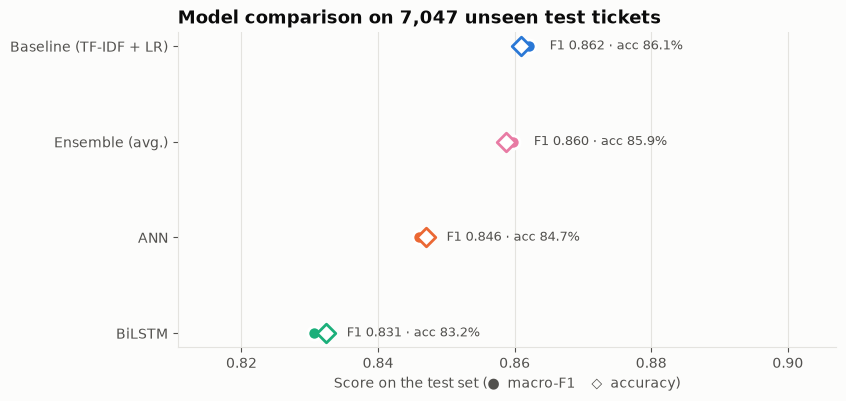

In [5]:
# Dot plot: differences are a few points, so dots on a zoomed axis show them honestly (bars would need a zero baseline).
order = comparison.sort_values("macro_f1").index
fig, ax = plt.subplots(figsize=(8.5, 0.7 * len(order) + 1.3))
for y, name in enumerate(order):
    r = comparison.loc[name]
    ax.plot([r.macro_f1, r.accuracy], [y, y], color="#d4d3cf", linewidth=2, zorder=1)
    ax.scatter(r.macro_f1, y, s=90, color=MODELS[r.key]["color"], zorder=3, edgecolor="white", linewidth=2)
    ax.scatter(r.accuracy, y, s=90, marker="D", color="white", edgecolor=MODELS[r.key]["color"], linewidth=2, zorder=3)
    ax.text(max(r.macro_f1, r.accuracy) + 0.003, y, f"F1 {r.macro_f1:.3f} · acc {r.accuracy:.1%}", va="center", fontsize=9, color=TEXT_SECONDARY)
ax.set_yticks(range(len(order)), order)
lo = comparison[["macro_f1", "accuracy"]].min().min()
ax.set_xlim(lo - 0.02, comparison[["macro_f1", "accuracy"]].max().max() + 0.045)
ax.set_xlabel("Score on the test set (●  macro-F1    ◇  accuracy)")
ax.grid(axis="y", visible=False)
ax.set_title("Model comparison on 7,047 unseen test tickets")
save(fig, "21_model_comparison")
plt.show()

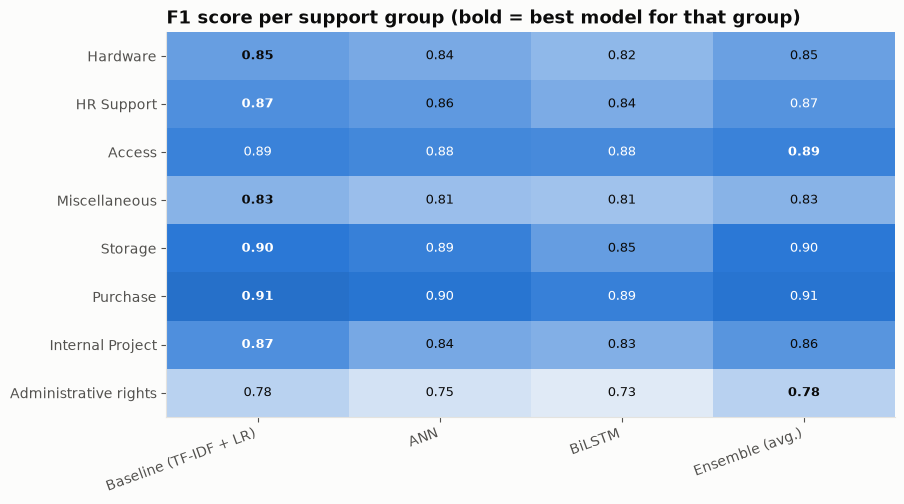

,Baseline (TF-IDF + LR),ANN,BiLSTM,Ensemble (avg.)
Hardware,0.852,0.838,0.820,0.849
HR Support,0.870,0.857,0.836,0.866
Access,0.887,0.880,0.877,0.888
Miscellaneous,0.827,0.812,0.807,0.826
Storage,0.899,0.889,0.853,0.899
Purchase,0.913,0.904,0.890,0.906
Internal Project,0.870,0.839,0.830,0.864
Administrative rights,0.780,0.748,0.733,0.781


In [6]:
f1_table = pd.DataFrame({MODELS[k]["name"]: per_class_report(y_test, pred(P_test[k])).f1 for k in all_keys}).reindex(LABELS)
f1_table.to_csv(RESULTS_DIR / "final_per_class_f1.csv")

fig, ax = plt.subplots(figsize=(1.6 * len(all_keys) + 3, 5))
lo = np.floor(f1_table.values.min() * 20) / 20
ax.imshow(f1_table.values, cmap=CM_CMAP, vmin=lo, vmax=1.0, aspect="auto")
for i in range(len(LABELS)):
    best_j = f1_table.values[i].argmax()
    for j in range(len(all_keys)):
        v = f1_table.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9.5,
                color="white" if (v - lo) / (1 - lo) > 0.55 else TEXT, fontweight="bold" if j == best_j else "normal")
ax.set_xticks(range(len(all_keys)), f1_table.columns, rotation=20, ha="right")
ax.set_yticks(range(len(LABELS)), LABELS)
ax.grid(False)
ax.set_title("F1 score per support group (bold = best model for that group)")
save(fig, "22_per_class_f1_heatmap")
plt.show()
f1_table.round(3)

## 4. Confidence-based routing
Auto-route confident tickets, send the rest to a person.

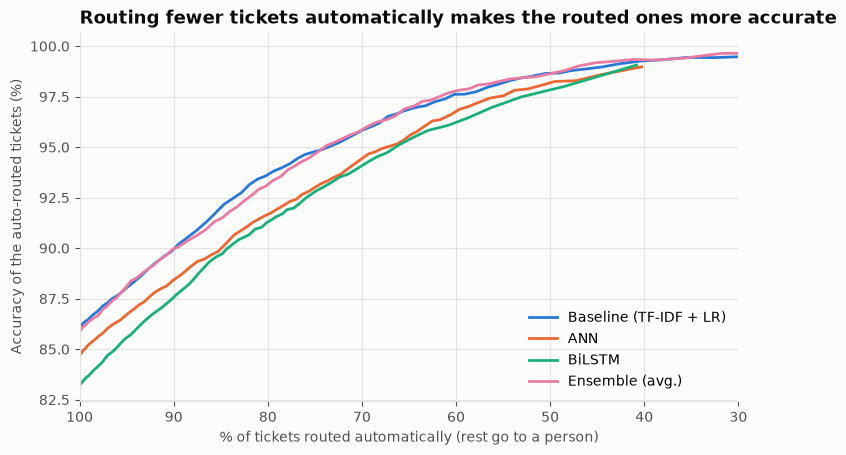

In [7]:
def coverage_curve(p, y, thresholds):
    conf, correct = p.max(1), pred(p) == y
    return pd.DataFrame([{"threshold": t, "coverage": (conf >= t).mean(),
                          "accuracy": correct[conf >= t].mean() if (conf >= t).any() else np.nan} for t in thresholds])

TH = np.round(np.arange(0.0, 1.0, 0.01), 2)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for k in all_keys:
    c = coverage_curve(P_test[k], y_test, TH)
    ax.plot(c.coverage * 100, c.accuracy * 100, color=MODELS[k]["color"], linewidth=2, label=MODELS[k]["name"])
ax.set_xlim(100, 30)
ax.set_xlabel("% of tickets routed automatically (rest go to a person)")
ax.set_ylabel("Accuracy of the auto-routed tickets (%)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Routing fewer tickets automatically makes the routed ones more accurate")
save(fig, "23_coverage_vs_accuracy")
plt.show()

### Operating point
Lowest threshold giving ≥ 95% accuracy on validation, then reported on test.

In [8]:
TARGET = 0.95
best_single = max(keys, key=lambda k: f1_score(y_val, pred(P_val[k]), average="macro"))
ops = []
for k in [best_single, "ensemble"]:
    cv = coverage_curve(P_val[k], y_val, TH)
    t = float(cv[cv.accuracy >= TARGET].threshold.min())
    ct = coverage_curve(P_test[k], y_test, [t]).iloc[0]
    conf, correct = P_test[k].max(1), pred(P_test[k]) == y_test
    ops.append({"model": MODELS[k]["name"], "key": k, "threshold (chosen on val)": t,
                "test: % auto-routed": ct.coverage * 100, "test: accuracy of auto-routed": ct.accuracy * 100,
                "test: % to human review": (1 - ct.coverage) * 100,
                "test: share of all errors caught by review": (~correct & (conf < t)).sum() / (~correct).sum() * 100,
                "test: accuracy with no threshold": correct.mean() * 100})
ops = pd.DataFrame(ops).set_index("model")
(RESULTS_DIR / "threshold_summary.json").write_text(ops.reset_index().to_json(orient="records", indent=2))
ops.drop(columns="key").round(2).T

model,Baseline (TF-IDF + LR),Ensemble (avg.)
threshold (chosen on val),0.68,0.71
test: % auto-routed,70.85,70.36
test: accuracy of auto-routed,95.61,95.76
test: % to human review,29.15,29.64
test: share of all errors caught by review,77.65,78.92
test: accuracy with no threshold,86.09,85.87


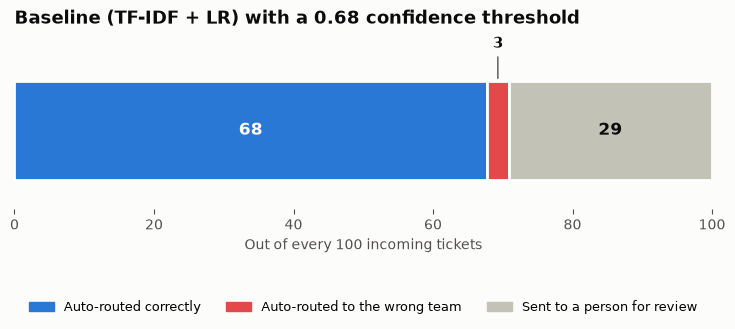

Baseline (TF-IDF + LR) {'threshold (chosen on val)': 0.7, 'test: % auto-routed': 70.9, 'test: accuracy of auto-routed': 95.6, 'test: % to human review': 29.1, 'test: share of all errors caught by review': 77.7, 'test: accuracy with no threshold': 86.1}


In [9]:
# The headline picture for the Conclusion: what happens to 100 incoming tickets with the chosen rule.
op = ops.iloc[0] if ops.iloc[0]["test: accuracy of auto-routed"] >= ops.iloc[1]["test: accuracy of auto-routed"] - 0.5 and ops.iloc[0]["test: % auto-routed"] >= ops.iloc[1]["test: % auto-routed"] else ops.iloc[1]
op_name = op.name
auto = op["test: % auto-routed"]
auto_ok = auto * op["test: accuracy of auto-routed"] / 100
review = 100 - auto
parts = [("Auto-routed correctly", auto_ok, "#2a78d6"), ("Auto-routed to the wrong team", auto - auto_ok, "#e34948"),
         ("Sent to a person for review", review, "#c3c2b7")]
fig, ax = plt.subplots(figsize=(9, 2.3))
left = 0
for lab, v, c in parts:
    ax.barh(0, v, left=left, color=c, height=0.5, edgecolor="white", linewidth=2)
    if v >= 4:
        ax.text(left + v / 2, 0, f"{v:.0f}", ha="center", va="center", color="white" if c != "#c3c2b7" else TEXT, fontsize=12, fontweight="bold")
    else:
        ax.annotate(f"{v:.0f}", (left + v / 2, 0.25), xytext=(left + v / 2, 0.42), ha="center", fontsize=11, fontweight="bold",
                    color=TEXT, arrowprops=dict(arrowstyle="-", color=TEXT_SECONDARY, lw=1))
    left += v
ax.set_xlim(0, 100)
ax.set_yticks([])
ax.set_xlabel("Out of every 100 incoming tickets")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for _, _, c in parts]
ax.legend(handles, [p[0] for p in parts], frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.45), fontsize=9)
ax.set_ylim(-0.4, 0.5)
ax.set_title(f"{op_name} with a {op['threshold (chosen on val)']:.2f} confidence threshold")
save(fig, "24_routing_outcome_per_100")
plt.show()
print(op_name, op.drop("key").astype(float).round(1).to_dict())

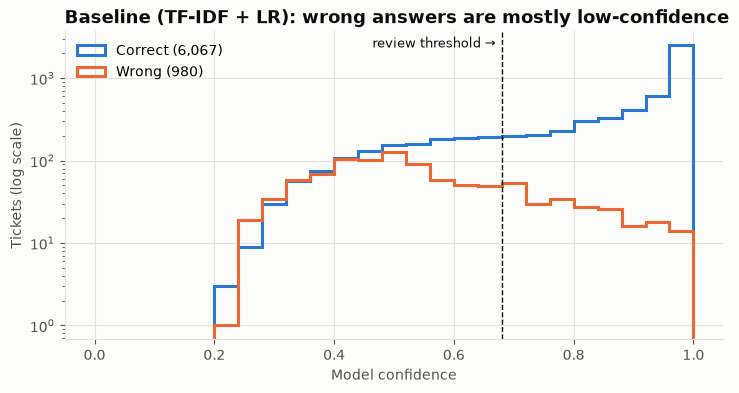

In [10]:
k = ops.loc[op_name, "key"]
conf, correct = P_test[k].max(1), pred(P_test[k]) == y_test
bins = np.linspace(0, 1, 26)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hist(conf[correct], bins=bins, histtype="step", color="#2a78d6", linewidth=2.2, label=f"Correct ({correct.sum():,})")
ax.hist(conf[~correct], bins=bins, histtype="step", color="#eb6834", linewidth=2.2, label=f"Wrong ({(~correct).sum():,})")
ax.axvline(op["threshold (chosen on val)"], color=TEXT, linestyle="--", linewidth=1)
ax.text(op["threshold (chosen on val)"] - 0.01, ax.get_ylim()[1] * 0.9, "review threshold →", ha="right", fontsize=9, color=TEXT)
ax.set_yscale("log")
ax.set_xlabel("Model confidence")
ax.set_ylabel("Tickets (log scale)")
ax.legend(frameon=False, loc="upper left")
ax.set_title(f"{op_name}: wrong answers are mostly low-confidence")
save(fig, "25_confidence_correct_vs_wrong")
plt.show()

## 5. Error analysis

Best model by validation macro-F1: Baseline (TF-IDF + LR)


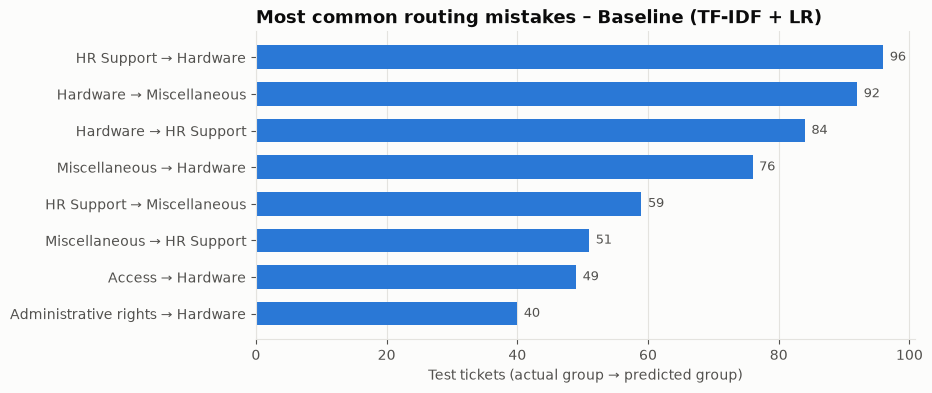

,actual,predicted,tickets,% of actual group
0,HR Support,Hardware,96.0,6.0
1,Hardware,Miscellaneous,92.0,4.6
2,Hardware,HR Support,84.0,4.2
3,Miscellaneous,Hardware,76.0,7.2
4,HR Support,Miscellaneous,59.0,3.7
5,Miscellaneous,HR Support,51.0,4.9
6,Access,Hardware,49.0,4.6
7,Administrative rights,Hardware,40.0,15.3


In [11]:
best_key = comparison.sort_values("val_macro_f1", ascending=False).iloc[0].key
print("Best model by validation macro-F1:", MODELS[best_key]["name"])
cm = confusion_matrix(y_test, pred(P_test[best_key]), labels=LABELS)
pairs = (pd.DataFrame(cm, index=LABELS, columns=LABELS).where(~np.eye(8, dtype=bool)).stack()
           .sort_values(ascending=False).head(8).rename("tickets").rename_axis(["actual", "predicted"]).reset_index())
pairs["% of actual group"] = [cm[LABELS.index(a)].sum() for a in pairs.actual]
pairs["% of actual group"] = (pairs.tickets / pairs["% of actual group"] * 100).round(1)

fig, ax = plt.subplots(figsize=(8.5, 4))
lab = [f"{a} → {p}" for a, p in zip(pairs.actual, pairs.predicted)][::-1]
ax.barh(lab, pairs.tickets[::-1], color=SERIES, height=0.65)
for y, v in enumerate(pairs.tickets[::-1]):
    ax.text(v + 1, y, f"{int(v)}", va="center", fontsize=9, color=TEXT_SECONDARY)
ax.set_xlabel("Test tickets (actual group → predicted group)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Most common routing mistakes – {MODELS[best_key]['name']}")
save(fig, "26_top_confusions")
plt.show()
pairs

### Shared mistakes across models

In [12]:
wrong = pd.DataFrame({MODELS[k]["name"]: pred(P_test[k]) != y_test for k in keys})
n_wrong = wrong.sum(axis=1)
agree = pd.Series({f"wrong in {i} of {len(keys)} models": int((n_wrong == i).sum()) for i in range(len(keys) + 1)})
print(agree.to_string())
print(f"\nTickets every model gets wrong: {(n_wrong == len(keys)).sum()} ({(n_wrong == len(keys)).mean():.1%} of test set)")

wrong in 0 of 3 models    5403
wrong in 1 of 3 models     639
wrong in 2 of 3 models     415
wrong in 3 of 3 models     590

Tickets every model gets wrong: 590 (8.4% of test set)


In [13]:
hard = test[n_wrong == len(keys)].copy()
for k in keys:
    hard[MODELS[k]["name"]] = pred(P_test[k])[n_wrong == len(keys)]
hard["all models agree"] = hard[[MODELS[k]["name"] for k in keys]].nunique(axis=1) == 1
hard["mean confidence"] = np.mean([P_test[k].max(1) for k in keys], axis=0)[n_wrong == len(keys)]
hard.to_csv(RESULTS_DIR / "hard_tickets.csv", index=False)
print(f"Of these, all models agree on the same (different) answer: {hard['all models agree'].mean():.0%}")
hard[hard["all models agree"]].sort_values("mean confidence", ascending=False)[["text", "label", MODELS[keys[0]]["name"], "mean confidence"]].head(15).round(2)

Of these, all models agree on the same (different) answer: 78%


,text,label,Baseline (TF-IDF + LR),mean confidence
767,access to friday pm error dear receiving error please attached asking please thank head,Hardware,HR Support,1.00
4005,wants to access bucharest wednesday july wants hello please location since upload organize files kind regards accept...,HR Support,Storage,0.99
1976,enter time oracle pm va leave maternity leave ext friday re pare maternity leave care precedent si card cannot saved...,Hardware,HR Support,0.99
3357,add new team member to git wednesday november pm re add member latest he according please fix give rights over manag...,Access,Miscellaneous,0.99
1576,having issues with the loaner having issues with loaner,Hardware,Administrative rights,0.99
6797,access to ms project thursday pm hi please added licence cost code thanks,Access,Internal Project,0.99
5868,timecards available available intr meeting fill leave si maternity leave leave si ca la pot submit la timecard timec...,Hardware,HR Support,0.99
2483,reset time card card hi guys please card period thank application engineer,HR Support,Access,0.99
3134,add belgrade to list add hi ask add public please addresses needed thanks,HR Support,Miscellaneous,0.98
6684,wants to access lost permissions wants access for also actively proxy po weird having access accounts when did chang...,Hardware,Storage,0.98


In [14]:
hard[~hard["all models agree"]].sample(min(10, (~hard["all models agree"]).sum()), random_state=1)[["text", "label"] + [MODELS[k]["name"] for k in keys]]

,text,label,Baseline (TF-IDF + LR),ANN,BiLSTM
5706,admin console permissions console permissions hello migration require console delete fresh install without step boot...,Hardware,Purchase,Administrative rights,Storage
5552,docking station request tuesday december pm docking station importance high hi log he has requested docking station ...,Purchase,Hardware,HR Support,HR Support
2098,cross validation rules please cancel friday pm re cross validation rules please cancel hi please call thank friday p...,Hardware,Miscellaneous,HR Support,Miscellaneous
6494,returns returns for apple devices,Hardware,Purchase,Purchase,Access
3061,user credentials sent tuesday july credentials our pipeline can use en connect,Internal Project,Access,Administrative rights,Access
3867,file lost file lost hi lost important file computer know how file cracked saved another file over file was opens ple...,Access,Hardware,Storage,Storage
5217,new project request de march pm re hi thank explanations about key great thank march re hi few notes ongoing codes y...,Administrative rights,Internal Project,Hardware,Hardware
2686,pas reporting view timeout error shift left re view timeout error dear taking mind fix out issue mainly self cannot ...,Access,Hardware,Hardware,HR Support
3104,import list migrate hello migrated gold link also granted control permissions best regards engineer thursday march p...,HR Support,Hardware,Storage,Hardware
6397,problems receiving mails problems receiving mails hello have trouble receiving mails following address please help b...,Administrative rights,Hardware,Hardware,Miscellaneous


### Takeaways
- ~8% of test tickets are wrong for every model, mostly with the same alternative answer → likely mislabels (e.g. timecard tickets labelled Hardware) or vague tickets.
- Confusions concentrate among Hardware, HR Support and Miscellaneous; the confidence threshold, not a bigger model, makes automation safe.